In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install optuna
!pip install flowio

!pip install git+https://github.com/enricodidoli-source/memory-save.git
!pip install git+https://github.com/enricodidoli-source/seed-manager.git

import os

os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'  # For CuDNN ops

import optuna
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import pickle
import time
import yaml
import tensorflow as tf
from tensorflow import keras
import glob


from memory_utils import clear_RAM, MemorySave
from seed_manager import SeedManager

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for flowio: filename=flowio-1.4.0-py3-none-any.whl size=21898 sha256=6fee5a1910b8dac06fe5df87091302a1cc015109fd07b24471082cfcbca0ced5
  Stored in directory: /root/.cache/pip/wheels/8b/6d/0e/187be3e520a5baa75a82dc8b3097ba017869e67af8255d2fc2
Successfully built flowio
  Cloning https://github.com/enricodidoli-source/memory-save.git to /tmp/pip-req-build-wvpyft_0
  Running command git clone --filter=blob:none --quiet https://github.com/enricodidoli-source/memory-save.git /tmp/pip-req-build-wvpyft_0
  Resolved https://github.com/enricodidoli-source/memory-save.git to commit d05184c0a81d04b07de08c3c0ccc3bae7724f2d8
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for memory-save: filena

In [3]:

fixed_path = '/content/drive/MyDrive/BinCellCNN/'
#fixed_path = 'C:/Users/admin/BinCellCNN/'

if fixed_path not in sys.path:
    sys.path.append(fixed_path)

modules_dir = f'{fixed_path}src/'
if modules_dir not in sys.path:
    sys.path.append(modules_dir)


whole_exp = 'clinical_try_1'


experiment_path = f'{fixed_path}experiments/experiment_{whole_exp}/'
os.makedirs(experiment_path, exist_ok=True)

config_file_path = os.path.join(experiment_path, "train_clinical_config.yml")
with open(config_file_path, "r") as f:
    config = yaml.safe_load(f)

# --- Data ---
train_data_folder_path = config['train_data_folder_path']
data_label = config['data_label']
extension = config['extension']
remove_columns = config['remove_columns']

# --- Seed parameters ---
starting_seed = config['starting_seed']

# --- Environment parameters ---
colab = config['colab']
save_memory = config['save_memory']

# --- Model Parameters ---
eval_metric = config['eval_metric']

n_patients = config['n_patients']


for key, value in config.items():
    print(f"{key}: {value}")

colab = True
if colab:
    mem_path = '/content/temp_data'
else:
    mem_path = f'{fixed_path}/temp_data'

mem = MemorySave(base_dir = mem_path)




data_label: IsBlast
extension: *.csv
remove_columns: ['Original_ID']
train_data_folder_path: /content/drive/MyDrive/BinCellCNN/train_samples/
starting_seed: 42
save_memory: True
colab: False
n_patients: 6
eval_metric: f1_score
bayesian_comb: 1
BO_tuning_epochs: 1
BO_tuning_nruns: 3
BO_grid: False
BO_trials: 1
ncells_step: 100
min_ncells: 100
max_ncells: 200
nsub_step: 5
min_nsubs: 5
max_nsubs: 10
bs_step: 100
min_bs: 100
max_bs: 400
tuning_epochs: 1
tuning_nruns: 3
grid: False
trials: 1
nfilter: [5, 7, 9]
maxpool_p: [0.01, 1, 10, 100]
learning_r: [0.001, 0.005]


In [4]:

decache_files = ['src.shared.utils', 'src.shared.timepoints_elaboration', 'src.shared.temp_storage', 'src.shared.cv_folds',
                 'src.sample_level.bayesian_tuning', 'src.sample_level.show_results', 'src.sample_level.training',
                 'src.sample_level.testing', 'src.sample_level.pipelines', 'src.sample_level.bayesian_tuning', 'src.BinCellCNN.model']

# Remove from cache
from src.shared.utils import remove_from_cache
remove_from_cache(decache_files)

from src.shared.timepoints_elaboration import load_data
from src.sample_level.show_results import show_blast_distribution_perc
from src.BinCellCNN.model import BinCellCNN
from src.clinical import generate_clinical_folds, tuning_and_train_model

src.shared.utils removed from cache
src.shared.timepoints_elaboration not found in cache
src.shared.temp_storage not found in cache
src.shared.cv_folds not found in cache
src.sample_level.bayesian_tuning not found in cache
src.sample_level.show_results not found in cache
src.sample_level.training not found in cache
src.sample_level.testing not found in cache
src.sample_level.pipelines not found in cache
src.sample_level.bayesian_tuning not found in cache
src.BinCellCNN.model not found in cache


# Single Cell Run

/content/drive/MyDrive/BinCellCNN/train_samples/
        Unnamed: 0     FSC-A     FSC-H     SSC-A  CD81(FITC-A)  \
0              0.0  0.823705  0.981191  0.472020      1.499401   
1              1.0  0.615591  0.760397  0.477505      2.580347   
2              2.0  1.057331  1.323201  0.529439      2.071182   
3              3.0  0.700533  0.886617  0.511572      1.912328   
4              4.0  1.140657  1.397196  0.534744      1.689729   
...            ...       ...       ...       ...           ...   
778745    778745.0  0.886183  1.061743  0.450470      1.840345   
778746    778746.0  0.715778  0.901882  0.456647      2.303418   
778747    778747.0  0.544148  0.666834  0.441484      2.124923   
778748    778748.0  0.894327  1.153077  0.542693      2.330696   
778749    778749.0  0.408520  0.483337  0.581194      0.800680   

        CD73+CD304(PE-A)  CD34(PerCP-Cy5-5-A)  CD19(PE-Cy7-A)  CD10(APC-A)  \
0               0.240827             1.125403        2.439297     0.699008   
1 

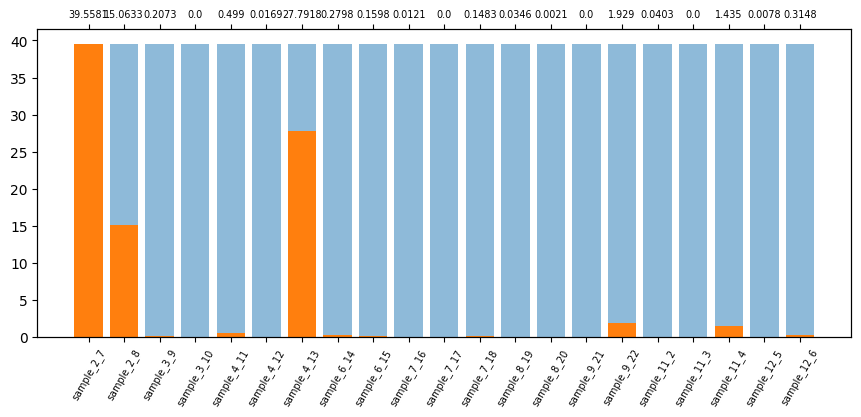

[np.float64(39.5581), np.float64(15.0633), np.float64(0.2073), np.float64(0.0), np.float64(0.499), np.float64(0.0169), np.float64(27.7918), np.float64(0.2798), np.float64(0.1598), np.float64(0.0121), np.float64(0.0), np.float64(0.1483), np.float64(0.0346), np.float64(0.0021), np.float64(0.0), np.float64(1.929), np.float64(0.0403), np.float64(0.0), np.float64(1.435), np.float64(0.0078), np.float64(0.3148)]
CPU times: user 1min 27s, sys: 14.8 s, total: 1min 42s
Wall time: 1min 51s


In [9]:
%%time
temp_mem = None
multiple_donations, all_datasets, samples_ids = load_data(train_data_folder_path, ext = extension, mem = mem, remove_columns = remove_columns)
tot_perc_list = show_blast_distribution_perc(ALL_DATASETS = all_datasets,
                                             multiple_donations = multiple_donations,
                                             return_perc = True,
                                             samples_ids = samples_ids,
                                             mem = mem)


print(tot_perc_list)


In [10]:
%%time

seed_manager = SeedManager(starting_seed=starting_seed)


train_kfolds = generate_clinical_folds(multiple_donations = multiple_donations,
                                  ALL_DATASETS= all_datasets,
                                  folds = 3,
                                  label_column = data_label,
                                  mem = mem,
                                  seed_manager = seed_manager)



base_path /content/temp_data/temp_var/ALL_DATASETS
['df_0.parquet', 'df_1.parquet', 'df_10.parquet', 'df_11.parquet', 'df_12.parquet', 'df_13.parquet', 'df_14.parquet', 'df_15.parquet', 'df_16.parquet', 'df_17.parquet', 'df_18.parquet', 'df_19.parquet', 'df_2.parquet', 'df_20.parquet', 'df_3.parquet', 'df_4.parquet', 'df_5.parquet', 'df_6.parquet', 'df_7.parquet', 'df_8.parquet', 'df_9.parquet']
CV_seed 191664963
Remaining Patients: healthy = [], unhealthy = ['2', '4', '6', '8', '12'], mixed = ['3', '7', '9', '11']
All Patients in Train + Validation set: ['2', '3', '4', '7', '6', '9', '8', '11', '12']
Folds: [['4', '7', '3'], ['2', '9', '11'], ['8', '12', '6']]
Combination 1: (['4', '7', '3', '2', '9', '11'], ['8', '12', '6'])
Combination 2: (['2', '9', '11', '8', '12', '6'], ['4', '7', '3'])
Combination 3: (['4', '7', '3', '8', '12', '6'], ['2', '9', '11'])
CPU times: user 4.7 s, sys: 1.86 s, total: 6.56 s
Wall time: 5.76 s


In [11]:
%%time

CV_models, best_thr = tuning_and_train_model(BinCellCnn = BinCellCNN,
                                                          config = config,
                                                          experiment_path = experiment_path,
                                                          train_kfolds = train_kfolds,
                                                          multiple_donations = multiple_donations,
                                                          ALL_DATASETS = all_datasets,
                                                          mem = mem,
                                                          seed_manager = seed_manager)




[I 2026-11-06 20:24:35,438] A new study created in memory with name: no-name-837d1641-480e-4bcd-ac4f-bbce251b5a1a


{'ncells': (100, 200, 100), 'nsubs': (5, 10, 5), 'bs': (100, 400, 100)}
Start Bayesian Search for optimal ncells and nsubs parameters
LOPO fold 0: Optuna sampler seed = 1662057957
Model 1
Testing params -> ncells: 200, nsubs: 10, bs: 200
5 Fold CV started

Fold: 0

base_path /content/temp_data/temp_var/ALL_DATASETS
['df_0.parquet', 'df_1.parquet', 'df_10.parquet', 'df_11.parquet', 'df_12.parquet', 'df_13.parquet', 'df_14.parquet', 'df_15.parquet', 'df_16.parquet', 'df_17.parquet', 'df_18.parquet', 'df_19.parquet', 'df_2.parquet', 'df_20.parquet', 'df_3.parquet', 'df_4.parquet', 'df_5.parquet', 'df_6.parquet', 'df_7.parquet', 'df_8.parquet', 'df_9.parquet']
base_path /content/temp_data/temp_var/ALL_DATASETS
['df_0.parquet', 'df_1.parquet', 'df_10.parquet', 'df_11.parquet', 'df_12.parquet', 'df_13.parquet', 'df_14.parquet', 'df_15.parquet', 'df_16.parquet', 'df_17.parquet', 'df_18.parquet', 'df_19.parquet', 'df_2.parquet', 'df_20.parquet', 'df_3.parquet', 'df_4.parquet', 'df_5.parquet', 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - f1_score: 0.5152 - loss: 0.6999

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - f1_score: 0.5152 - loss: 0.6999 - val_f1_score: 0.4783 - val_loss: 0.6907
base_path /content/temp_data/temp_var/valid_samples
['df_0.parquet', 'df_1.parquet', 'df_2.parquet', 'df_3.parquet', 'df_4.parquet', 'df_5.parquet']


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but Sta

Loading from Temp
Loading from Temp
base_path /content/temp_data/temp_var/valid_samples
['df_0.parquet', 'df_1.parquet', 'df_2.parquet', 'df_3.parquet', 'df_4.parquet', 'df_5.parquet']
base_path /content/temp_data/temp_var
len(test_samples) 6
len(test_datasets_no_labels) 6
seed: 942484272. Type: <class 'int'>
seed: 942484272. Type: <class 'int'>
samples length [208000]
test_samples_length: 1


... (94 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
y_pred [[[0.4959895  0.50401044]]

 [[0.49213624 0.50786382]]

 [[0.50670761 0.49329239]]]
np.mean(y_pred, axis=0) [[0.49827778 0.50172222]]
Done
test_pred [[0.49827778 0.50172222]]
test_pred[0] [0.49827778 0.50172222]
seed: 1634535062. Type: <class 'int'>
seed: 1634535062. Type: <class 'int'>
samples length [637409]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 554ms/step
test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
test_samples_length: 1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step
y_pred [[[0.49685192 0.50314802]]

 [[0.49426112 0.50573897]]

 [[0.50755054 0.49244946]]]
np.mean(y_pred, axis=0) [[0.49955452 0.50044549]]
Done
test_pred [[0.49955452 0.50044549]]
test_pred[0] [0.49955452 0.50044549]
Trial 1 Done!

predictions_list [[np.float64(0.5033441781997681), np.float64(0.5019132097562155), np.float64(0.5009959042072296), np.float64(0.500086267789205), np.float64(0.4997248947620392), np.float64(0.5017222166061401), np.float64(0.5004454851150513)]]
original_val_y [1, 1, 0, 1, 1, 0, 1]
Trial 0 Accuracy: 0.5714285714285714
Trial 0 F1_score: 0.7272727272727273
Trial 0 Recall: 0.8
Trial 0 Precision: 0.6666666666666666
             0  1  2  3  4  5  6
0            1  1  1  1  0  1  1
True Labels  1  1  0  1  1  0  1
mean_accuracy over the ten trials: 0.5714285714285714
accuracy_std ov

In [ ]:
mem.close()
